# A MION-to-BOLD transform exists

This notebook is a proof of principle. It shows that a single convolutional kernel can transform a MION time series into the BOLD time series driven by the same neural activity.

Both species see one noise-free neural time course. BOLD and MION differ only in their hemodynamic response functions (HRFs), so any mismatch between them is purely temporal. The real brain is more complicated: not all signals are shared between species, or even similar, and that case is handled in [`learn_hrf_transform_mixed_signals.ipynb`](learn_hrf_transform_mixed_signals.ipynb).

In [1]:
%matplotlib inline
## Imports, and settings
import numpy as np

from mvta import bold_hrf, mion_hrf, plot_demo, plot_neural, simulate_movie, sse_kernel

tr = 1.0
duration = 32.0
kernel_seconds = 15.0  # kernel duration, in seconds. Must be a multiple of tr.
kernel_length = int(round(kernel_seconds / tr))
if abs(kernel_seconds - kernel_length * tr) > 1e-6:
    raise ValueError(f"kernel_seconds ({kernel_seconds}) must be a multiple of tr ({tr}).")

## Simulate one shared time course

The neural signal is an independent Uniform(0, 1) draw at every TR. It is convolved with the BOLD HRF to give the BOLD series and with the MION HRF to give the MION series, then each run is z-scored. There is one subject per species and one voxel per subject.

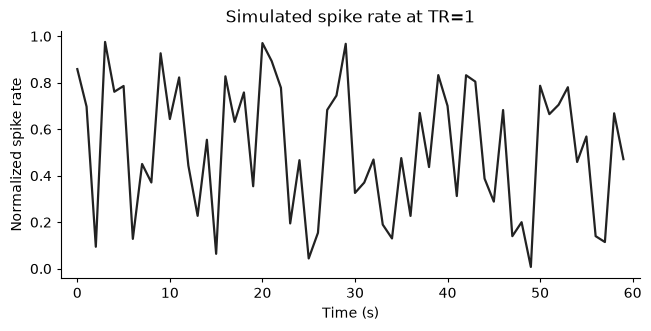

In [2]:
seed = 42
n_runs = 5
n_tr = 500

bold = bold_hrf(tr=tr, time_length=duration)
mion = mion_hrf(tr=tr, time_length=duration)
simulation = simulate_movie(
    bold,
    mion,
    n_tr=n_tr,
    tr=tr,
    n_runs=n_runs,
    n_subjects=1,
    n_voxels=1,
    n_shared=1,
    n_group=0,
    n_idio=0,
    n_signals_per_voxel=1,
    rng=seed,
)
bold_series = simulation.bold[0][:, 0]
mion_series = simulation.mion[0][:, 0]
fig = plot_neural(simulation.neural, simulation.run_index, tr)

## Learn the kernel with BFGS

The kernel $k$ is chosen to minimize the sum of squared errors (SSE) between BOLD and the convolved MION series,

$$
\mathrm{SSE}(k) = \sum_t \Big(\mathrm{BOLD}_t - \sum_{\ell=0}^{L-1} k_\ell \, \mathrm{MION}_{t-\ell}\Big)^2 .
$$

A kernel of length $L$ predicts each BOLD sample from the current MION sample and the $L-1$ before it. For the first $L-1$ samples of a run, some of those earlier MION samples fall before the run began and are missing, so these samples are left out of the SSE.

The SSE is minimized with BFGS, the same optimizer used for MVTA in the multivariate case. BFGS starts from a flat kernel whose weights sum to one. At each step it estimates how the SSE changes with each kernel weight, moves the kernel downhill, and refines an estimate of the curvature of the loss so later steps are better scaled. It stops when the SSE no longer decreases appreciably.

**Why SSE works here.** With one shared, noise-free time course, each BOLD sample has a known MION counterpart: the same neural signal at the same time. So there is a target the transformed MION should match. Because convolution is linear in the kernel, the SSE is a quadratic function of the kernel weights: smooth, convex, and bowl-shaped. It has a single minimum as long as no combination of kernel weights leaves the prediction unchanged, which holds here because the random neural input makes the lagged copies of MION linearly independent. BFGS therefore finds that minimum from any starting kernel.

**What changes in the multivariate case.** When voxels mix shared, species-specific, and subject-specific signals, no MION voxel has a BOLD voxel that it should equal. The voxels are not matched across species, and much of each voxel's signal may have no counterpart in the other species at all. Minimizing SSE against any particular BOLD series would push the kernel to fit signals that are not shared. MVTA therefore keeps the same optimizer and starting kernel but changes the loss: for each candidate kernel, it fits a shared space to the BOLD and transformed MION data and measures the cross-species mismatch there. That loss is no longer a simple quadratic in $k$, but BFGS is used in the same way.

**Kernel length.** The kernel is applied as a convolution, but finding it amounts to undoing the MION response and putting the BOLD response in its place. No kernel of finite length does this exactly, so the fit returns the best kernel of the chosen length. Its weights are close to zero after about 20 s. With these HRFs, a 15 s kernel explains about 99% of the BOLD variance, and longer kernels add only about 1%.

In [3]:
kernel, result = sse_kernel(
    bold_series,
    mion_series,
    simulation.run_index,
    kernel_length=kernel_length,
)
print(f"BFGS: {result.nit} iterations, converged: {result.success}")

kept = np.concatenate(
    [
        bold_series[simulation.run_index == run][kernel_length - 1 :]
        for run in np.unique(simulation.run_index)
    ]
)
total = np.sum((kept - kept.mean()) ** 2)
print(f"BOLD variance explained by the transformed MION: {1 - result.fun / total:.4f}")

BFGS: 16 iterations, converged: True
BOLD variance explained by the transformed MION: 0.9877


## Figure

BOLD is red, MION is blue, and the learned kernel and transformed MION series are black. Panel D shows 200–260 seconds, so the convolution edge at the start of the run is left out.

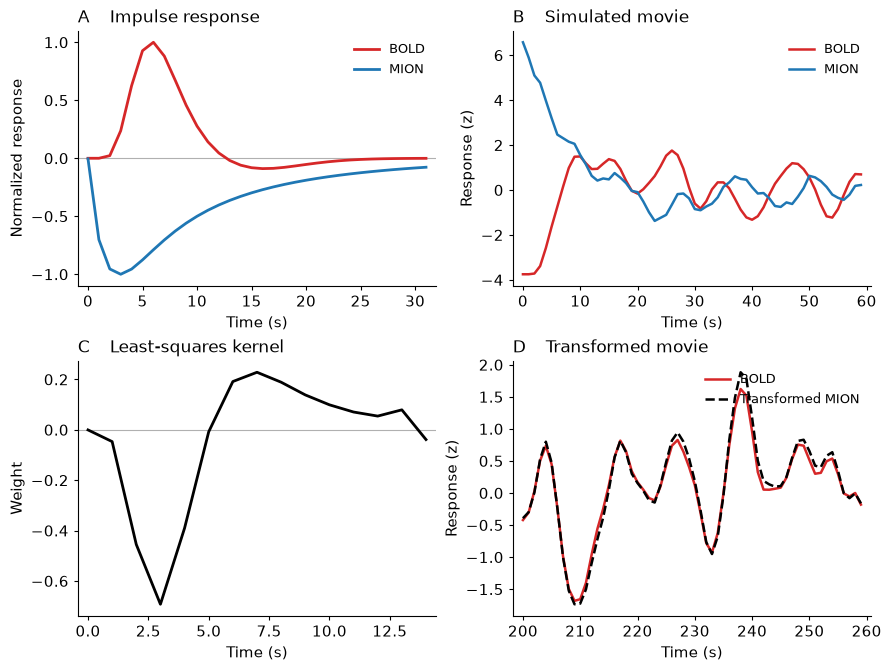

In [4]:
fig = plot_demo(
    bold,
    mion,
    tr=tr,
    bold_views=simulation.bold,
    mion_views=simulation.mion,
    run_index=simulation.run_index,
    kernel=kernel,
    corrected_window=(200.0, 260.0),
)